<a href="https://colab.research.google.com/github/eunnypark/iris-flower-classification/blob/main/%EB%B6%93%EA%BD%83%ED%92%88%EC%A2%85%EB%B6%84%EB%A5%98_%EB%A8%B8%EC%8B%A0%EB%9F%AC%EB%8B%9D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
# 입문

from sklearn.datasets import load_iris  # 붓꽃 데이터셋을 불러오는 함수 가져오기

iris = load_iris()  # 붓꽃 데이터셋을 불러와 iris 변수에 저장하기

print(iris.data[:5])  # 전체 데이터 중 앞의 5개 샘플의 측정값 출력하기
print(iris.target[:5])  # 앞의 5개 샘플에 해당하는 실제 품종 번호 출력하기

print(iris.target_names)  # 품종 번호가 각각 어떤 이름에 해당하는지 출력하기

print(iris.data.shape)  # 입력 데이터의 행과 열 개수 확인하기
print(iris.target.shape)  # 정답 데이터의 전체 크기 확인하기

[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]]
[0 0 0 0 0]
['setosa' 'versicolor' 'virginica']
(150, 4)
(150,)


In [7]:
# shape 알아보기

import numpy as np  # NumPy 라이브러리를 np라는 이름으로 가져오기

numbers = np.array([10, 20, 30, 40])  # 1차원 배열 생성

print(numbers.shape)  # 배열의 형태 확인

numbers = np.array([[1, 2, 3],  # 첫 번째 행
                    [4, 5, 6]]) # 두 번째 행

print(numbers.shape)  # 행과 열의 개수 확인

(4,)
(2, 3)


In [1]:
# 1차원배열 vs 2차원배열

import numpy as np  # NumPy 라이브러리 가져오기

a = np.array([0, 1, 2, 3])  # 1차원 배열 생성

b = np.array([[0], [1], [2], [3]])  # 2차원 배열 생성 (4행 1열)

print(a.shape)  # (4,)
print(b.shape)  # (4, 1)

(4,)
(4, 1)


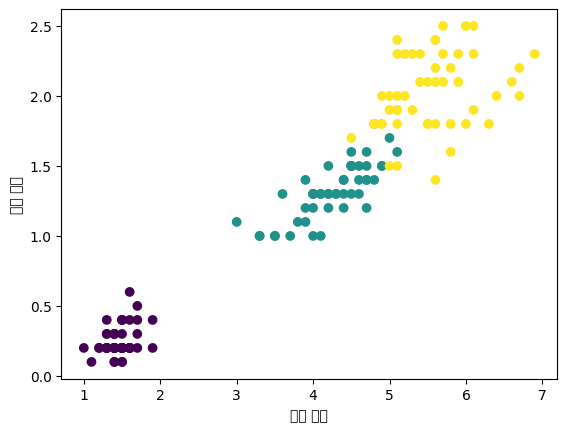

In [10]:
# 붓꽃 데이터의 구조를 이해하고 그래프로 살펴보기

import matplotlib.pyplot as plt  # 그래프를 그리기 위한 라이브러리 가져오기
from sklearn.datasets import load_iris  # 붓꽃 데이터셋을 불러오는 함수 가져오기

iris = load_iris()

# 붓꽃 데이터 구조 : 0 꽃받침길이 1 꽃받침너비 2 꽃잎길이 3 꽃잎너비

# 붓꽃 데이터에서 꽃잎 길이를 가져오기
petal_length = iris.data[:, 2] # : = 모두 선택 / 2 = 세번째 열 선택

# 붓꽃 데이터에서 꽃잎 너비를 가져오기
petal_width = iris.data[:, 3]

# 그래프의 가로축에 꽃잎 길이 지정
plt.xlabel("꽃잎 길이")

# 그래프의 세로축에 꽃잎 너비 지정
plt.ylabel("꽃잎 너비")

# 꽃잎 길이와 너비를 이용해 산점도 그리기. 실제 품종 번호에 따라 색깔 구분
plt.scatter(petal_length, petal_width, c=iris.target)

# 그래프 출력
plt.show()

In [8]:
# 머신러닝
# 1. 학습용 데이터 + 테스트 데이터로 나누기 (전체 데이터 150개 -> 120개 + 30개)
# 2. 모델 선택 : 첫 모델로 로지스틱 회귀 선택
# 3. 모델 학습 : fit()을 사용해 데이터의 패턴 학습
# 4. 품종 에측 : predict()로 새로운 붓꽃의 품종 예측
# 5. 성능 평가 : accuracy_score()로 예측 정확도 확인
# 6. 모델 비교 : 결정 트리와 랜덤 포레스트도 학습시켜 비교

#=====================================================================================

import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split  # 데이터를 학습용과 테스트용으로 분리하는 함수 가져오기
from sklearn.linear_model import LogisticRegression   # Scikit-learn에서 로지스틱 회귀 모델을 가져오기
from sklearn.metrics import accuracy_score # 모델의 예측 정확도를 계산하는 함수 가져오기

#=====================================================================================

iris = load_iris()

X = iris.data  # 입력 특성 150개를 X에 저장
y = iris.target  # 정답 150개를 y에 저장

X_train, X_test, y_train, y_test = train_test_split(
    X,  # 전체 입력 데이터
    y,  # 전체 정답 데이터
    test_size=0.2,  # 전체 데이터 중 20%를 테스트용으로 사용
    random_state=42,  # 실행할 때마다 동일하게 분리되도록 난수 고정
    stratify=y  # 품종별 비율이 학습용과 테스트용에 비슷하게 유지되도록 설정
)

print(X_train.shape)  # 학습용 입력 데이터의 크기 확인
print(X_test.shape)  # 테스트용 입력 데이터의 크기 확인
print(y_train.shape)  # 학습용 정답 데이터의 크기 확인
print(y_test.shape)  # 테스트용 정답 데이터의 크기 확인

model = LogisticRegression(max_iter=200) # 로지스틱 회귀 모델 생성. max_iter=200은 모델이 최적의 가중치를 찾기 위해 반복할 최대 횟수

model.fit(X_train, y_train)  # 학습용 입력 데이터와 정답 데이터를 사용해 모델 학습

# fit()은 모델이 입력 데이터와 정답 데이터 사이의 관계를 학습하도록 하는 메서드

print("학습된 가중치 : ", model.coef_)  # 학습된 각 특성의 가중치 출력
print("학습된 편향 : ", model.intercept_)  # 학습된 편향 출력

# fit()이 학습이라면 predict()는 예측

#=====================================================================================

predictions = model.predict(X_test[:5]) # 테스트 데이터 5개를 선택하여 품종 예측

print("예측 결과 : ", predictions)  # 모델이 예측한 품종 번호 출력
print("실제 정답 : ", y_test[:5]) # 실제 품종 번호 출력

#=====================================================================================

y_pred = model.predict(X_test) # 테스트 데이터 30개의 품종을 예측하여 y_pred에 저장

accuracy = accuracy_score(y_test, y_pred) # 실제 정답(y_test)과 예측 결과(y_pred)를 비교하여 정확도 계산

print("정확도:", accuracy) # 계산된 정확도 출력

#=====================================================================================



(120, 4)
(30, 4)
(120,)
(30,)
학습된 가중치 :  [[-5.29619995e-01  8.27358123e-01 -2.34726315e+00 -9.93463481e-01]
 [ 5.29726953e-01 -3.04865937e-01 -1.70965141e-01 -8.56157878e-01]
 [-1.06957382e-04 -5.22492185e-01  2.51822829e+00  1.84962136e+00]]
학습된 편향 :  [ 10.12541553   1.79802823 -11.92344376]
예측 결과 :  [0 2 1 1 0]
실제 정답 :  [0 2 1 1 0]
정확도: 0.9666666666666667


In [9]:
# 결정 트리로 동일한 분류 수행

from sklearn.tree import DecisionTreeClassifier # Scikit-learn에서 결정 트리 분류 모델 가져오기

iris = load_iris()

X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

tree_model = DecisionTreeClassifier(random_state=42) # 결정 트리 모델 생성
# random_state=42는 실행할 때 결과가 재현되도록 난수 고정

tree_model.fit(X_train, y_train) # 학습 데이터 120개를 사용하여 결정 트리 모델 학습

tree_pred = tree_model.predict(X_test) # 테스트 데이터 30개의 품종 예측

tree_accuracy = accuracy_score(y_test, tree_pred) # 실제 정답과 예측 결과를 비교하여 정확도 계산

print("결정 트리 정확도:", tree_accuracy) # 결정 트리 모델의 정확도 출력

결정 트리 정확도: 0.9333333333333333


In [12]:
# 결정 트리는 분류 규칙을 계속 만들어 나갈 수 있다.
# 그런데 규칙을 지나치게 복잡하게 만들면 학습 데이터에만 지나치게 잘 맞는 모델이 될 수 있다. -> 과적합

from sklearn.tree import DecisionTreeClassifier  # 결정 트리 분류 모델 가져오기
from sklearn.metrics import accuracy_score  # 정확도 계산 함수 가져오기

# 깊이를 제한하지 않은 결정 트리 생성
tree_deep = DecisionTreeClassifier(random_state=42)

# 학습 데이터로 모델 학습
tree_deep.fit(X_train, y_train)

# 학습 데이터에 대한 예측
train_pred = tree_deep.predict(X_train)

# 테스트 데이터에 대한 예측
test_pred = tree_deep.predict(X_test)

# 학습 데이터 정확도 계산
train_accuracy = accuracy_score(y_train, train_pred)

# 테스트 데이터 정확도 계산
test_accuracy = accuracy_score(y_test, test_pred)

# 두 정확도 출력
print("학습 정확도:", train_accuracy)
print("테스트 정확도:", test_accuracy)

학습 정확도: 1.0
테스트 정확도: 0.9333333333333333


In [13]:
# 과소적합

from sklearn.tree import DecisionTreeClassifier  # 결정 트리 모델 가져오기
from sklearn.metrics import accuracy_score  # 정확도 계산 함수 가져오기

# 최대 깊이를 1로 제한한 결정 트리 생성
tree_shallow = DecisionTreeClassifier(max_depth=1, random_state=42)

# 학습 데이터로 모델 학습
tree_shallow.fit(X_train, y_train)

# 학습 데이터 예측
train_pred = tree_shallow.predict(X_train)

# 테스트 데이터 예측
test_pred = tree_shallow.predict(X_test)

# 학습 데이터 정확도 계산
train_accuracy = accuracy_score(y_train, train_pred)

# 테스트 데이터 정확도 계산
test_accuracy = accuracy_score(y_test, test_pred)

# 결과 출력 -> 깊이가 너무 얕으면 과소적합!
print("학습 정확도:", train_accuracy)
print("테스트 정확도:", test_accuracy)

학습 정확도: 0.6666666666666666
테스트 정확도: 0.6666666666666666


In [3]:
# 랜덤 포레스트 : 여러 개의 결정 트리를 만들고, 각 트리의 예측을 종합하여 최종 결과를 결정하는 알고리즘

from sklearn.ensemble import RandomForestClassifier # Scikit-learn에서 랜덤 포레스트 분류 모델 가져오기

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split  # 데이터를 학습용과 테스트용으로 분리하는 함수 가져오기
from sklearn.metrics import accuracy_score

iris = load_iris()

X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

forest_model = RandomForestClassifier(  # 랜덤 포레스트 모델 생성
    n_estimators=100,   # n_estimators=100: 결정 트리 100개 사용
    random_state=42     # random_state=42: 실행 결과를 재현할 수 있도록 난수 고정
)

forest_model.fit(X_train, y_train)  # 학습 데이터로 랜덤 포레스트 모델 학습

forest_pred = forest_model.predict(X_test)  # 테스트 데이터의 붓꽃 품종 예측

forest_accuracy = accuracy_score(y_test, forest_pred) # 실제 정답과 예측 결과를 비교하여 정확도 계산

print("랜덤 포레스트 정확도:", forest_accuracy) # 정확도 출력


랜덤 포레스트 정확도: 0.9
